# Assignment 2
## Group C: Decision Trees
### Ivan Bibat
#### L00167791@atu.ie

## What are decision trees?

A decision tree is a classification algorithm that predicts by asking a series of yes/no questions about the features forming a flowchart, with questions such as "does the mushroom have no smell?".

- The decision tree is built with all the datapoints at the root-level initially. 

- Then every feature is tried and the data is split into groups with mostly one class. This is repeated on each group, building more branches, until the groups are pure or hits a depth limit. This is known as minimising the entropy (reducing disorder in the data)

- The final groups at the bottom are leaves, and each leaf predicts the most common class within it.


The purity of a tree is determined by the Gini Impurity metric, which is how the model decides to split nodes to form the tree. It is a measure from 0-0.5, where a group of only one class has a Gini of 0 (perfectly pure), or a 50/50 mix of the two classes with a score of 0.5.

- Predictions: a new mushroom starts at the root answers each question until it reaches a leaf. The leaf that the mushroom lands on is the prediction.

Decision Trees are a greedy algorithm, making the best decision at the current step, regardless of future outcomes.

Can a decision tree determine whether a mushroom is edible or poisonous based on its properties (its appearance, and smell?).

In [7]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [15]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.tree import DecisionTreeClassifier, plot_tree


1. UCI Mushrooms dataset

The dataset contains ~8000 mushrooms from 23 separate species of gilled mushrooms (Agaricus and Lepiota families), based on the Audubon Society Field Guide to North American Mushrooms. 

- Each mushroom has a label of edible or poisonous.
- Each mushroom has 22 features such as cap shape/colour, smell, gill size, and habitat.
- Each feature value is stored as a single-letter, such as odour n for no smell, or f for foul.

In [9]:
columns = [
    'class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor',
    'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color',
    'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring',
    'stalk-color-above-ring', 'stalk-color-below-ring',
    'veil-type', 'veil-color', 'ring-number', 'ring-type',
    'spore-print-color', 'population', 'habitat',
]

df = pd.read_csv("../data/mushrooms.data", names=columns)
df['class'] = df['class'].map({'e': 'edible', 'p': 'poisonous'})

print(f"Mushrooms: {len(df)}")
print(df['class'].value_counts())
df.head()


Mushrooms: 8124
class
edible       4208
poisonous    3916
Name: count, dtype: int64


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,poisonous,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,edible,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,edible,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,poisonous,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,edible,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [10]:
odour_names = {
    'a': 'almond', 'l': 'anise', 'c': 'creosote', 'y': 'fishy', 'f': 'foul',
    'm': 'musty', 'n': 'none', 'p': 'pungent', 's': 'spicy'
    }

pd.crosstab(df['odor'].map(odour_names), df['class'])

class,edible,poisonous
odor,,
almond,400,0
anise,400,0
creosote,0,192
fishy,0,576
foul,0,2160
musty,0,36
none,3408,120
pungent,0,256
spicy,0,576


Mushrooms that smell of almond and anise are always edible.

Those that smell of creosote, fishy, foul, musty, spicy, or pungent are always poisonous.

The main problem is those that have no smell `none`, of which 3408 are edible but 120 are poisonous. The decision tree will need to make more branches to be able to discern between them other than smell.

## 2. Encoding and splitting

The features need to be encoded into numbers as scikit learn's decision tree works with numbers only, not letters.

One-hot encoding converts each feature into various binary columns, one for each possible value.
For example, odor splits into several odor features, such as odor_a (almond?), odor_n (no smell?), etc.

The dataset is split 75:25 between the training and test set respectively, maintaining the ratio of edible to poisonous in each.

In [14]:
X = pd.get_dummies(df.drop(columns='class'))
y = df['class']

print(f"Features before encoding: {df.shape[1] - 1}")
print(f"Features after encoding:  {X.shape[1]}")
print([col for col in X.columns if col.startswith('odor')])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Training mushrooms: {len(X_train)}")
print(f"Test mushrooms:     {len(X_test)}")


Features before encoding: 22
Features after encoding:  117
['odor_a', 'odor_c', 'odor_f', 'odor_l', 'odor_m', 'odor_n', 'odor_p', 'odor_s', 'odor_y']
Training mushrooms: 6093
Test mushrooms:     2031


After encoding, the number of features go from 22 to 117.
There are now 9 separate odor columns, with 6093 mushrooms in training, and 2031 in testing.

## 3. Determining the Tree Depth

max_depth limits the amount of questions the decision tree can ask in a sequence. 

The shallower the tree, the more simple it is but it might miss deeper patterns in the data.
The deeper the tree, the higher the likelihood of it overfitting against the training data, creating branches for noise in training.

Each depth from 1 to 10 is validated with 5-fold cross validation during training. A mistake in identifying the mushroom could poison someone, accuracy by itself is insufficient.


In [17]:
results = []
for depth in range(1, 11):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)

    cv_pred = cross_val_predict(tree, X_train, y_train, cv=5)
    cm = confusion_matrix(y_train, cv_pred, labels=['edible', 'poisonous'])

    tree.fit(X_train, y_train)
    results.append({
        'max_depth': depth,
        'leaves': tree.get_n_leaves(),
        'train accuracy': accuracy_score(y_train, tree.predict(X_train)),
        'CV accuracy': accuracy_score(y_train, cv_pred),
        'poisonous predicted edible (CV)': cm[1, 0],   # row = actually poisonous, column = predicted edible
    })

results = pd.DataFrame(results).set_index('max_depth')
best_depth = results['CV accuracy'].idxmax()
print(f"Best depth: {best_depth}")
results.round(4)

Best depth: 8


,leaves,train accuracy,CV accuracy,poisonous predicted edible (CV)
max_depth,,,,
1,2,0.8881,0.8881,94
2,4,0.9552,0.9552,62
3,7,0.9860,0.9854,10
4,10,0.9943,0.9926,5
5,12,0.9998,0.9992,5
6,13,0.9998,0.9993,4
7,14,1.0000,0.9993,4
8,14,1.0000,0.9998,1
9,14,1.0000,0.9998,1


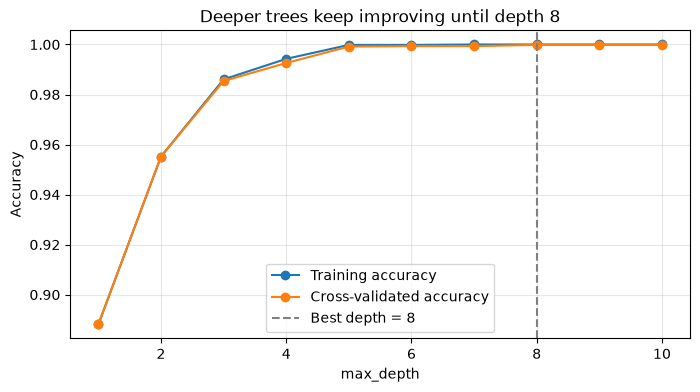

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(results.index, results['train accuracy'], marker='o', label='Training accuracy')
plt.plot(results.index, results['CV accuracy'], marker='o', label='Cross-validated accuracy')
plt.axvline(best_depth, color='grey', linestyle='--', label=f'Best depth = {best_depth}')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Deeper trees keep improving until depth 8')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
